In [1]:
%matplotlib inline
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import pandas as pd
import scipy
from scipy import stats
from scipy.optimize import curve_fit
import h5py
import pickle
import pandas as pd
from pathlib import Path

In [4]:
# File paths
path_qcd_250_500 = "uwphys434/Sample_pt_250_500-20261104T215933Z-1-001/Sample_pt_250_500/qcd_100000_pt_250_500.h5"
path_higgs_250_500 = "uwphys434/Sample_pt_250_500-20261104T215933Z-1-001/Sample_pt_250_500/higgs_100000_pt_250_500.h5"
path_qcd_1000_1200 = "uwphys434/Sample_pt_1000_1200-20261104T215930Z-1-001/Sample_pt_1000_1200/qcd_100000_pt_1000_1200.h5"
path_higgs_1000_1200 = "uwphys434/Sample_pt_1000_1200-20261104T215930Z-1-001/Sample_pt_1000_1200/higgs_100000_pt_1000_1200.h5"


# Function to inspect HDF5 file structure
def print_h5_structure(filepath):
    with h5py.File(filepath, 'r') as f:
        print(f"Structure for {filepath}:")
        def print_keys(name, obj):
            if isinstance(obj, h5py.Dataset):
                print(f"  Dataset: {name} | Shape: {obj.shape} | Type: {obj.dtype}")
        f.visititems(print_keys)
        print()

print_h5_structure(path_qcd_250_500)
print_h5_structure(path_higgs_250_500)
print_h5_structure(path_qcd_1000_1200)
print_h5_structure(path_higgs_1000_1200)

Structure for uwphys434/Sample_pt_250_500-20261104T215933Z-1-001/Sample_pt_250_500/qcd_100000_pt_250_500.h5:
  Dataset: qcd_100000_pt_250_500 | Shape: (100000, 14) | Type: float64

Structure for uwphys434/Sample_pt_250_500-20261104T215933Z-1-001/Sample_pt_250_500/higgs_100000_pt_250_500.h5:
  Dataset: higgs_100000_pt_250_500 | Shape: (100000, 14) | Type: float64

Structure for uwphys434/Sample_pt_1000_1200-20261104T215930Z-1-001/Sample_pt_1000_1200/qcd_100000_pt_1000_1200.h5:
  Dataset: qcd_100000_pt_1000_1200 | Shape: (100000, 14) | Type: float64

Structure for uwphys434/Sample_pt_1000_1200-20261104T215930Z-1-001/Sample_pt_1000_1200/higgs_100000_pt_1000_1200.h5:
  Dataset: higgs_100000_pt_1000_1200 | Shape: (100000, 14) | Type: float64



Mean value of each of the 14 columns:
QCD:   [ 4.4571e+02 -0.0000e+00 -0.0000e+00  9.7740e+01  9.0000e-02  0.0000e+00
  5.2100e+00  0.0000e+00  9.1000e-01  5.9000e-01  4.8000e-01  6.5000e-01
  8.1000e-01  3.2000e-01]
Higgs: [ 4.4739e+02 -0.0000e+00  0.0000e+00  1.1489e+02  1.3000e-01  0.0000e+00
  1.9700e+00  0.0000e+00  9.0000e-01  3.1000e-01  2.3000e-01  3.5000e-01
  7.6000e-01  5.3000e-01]


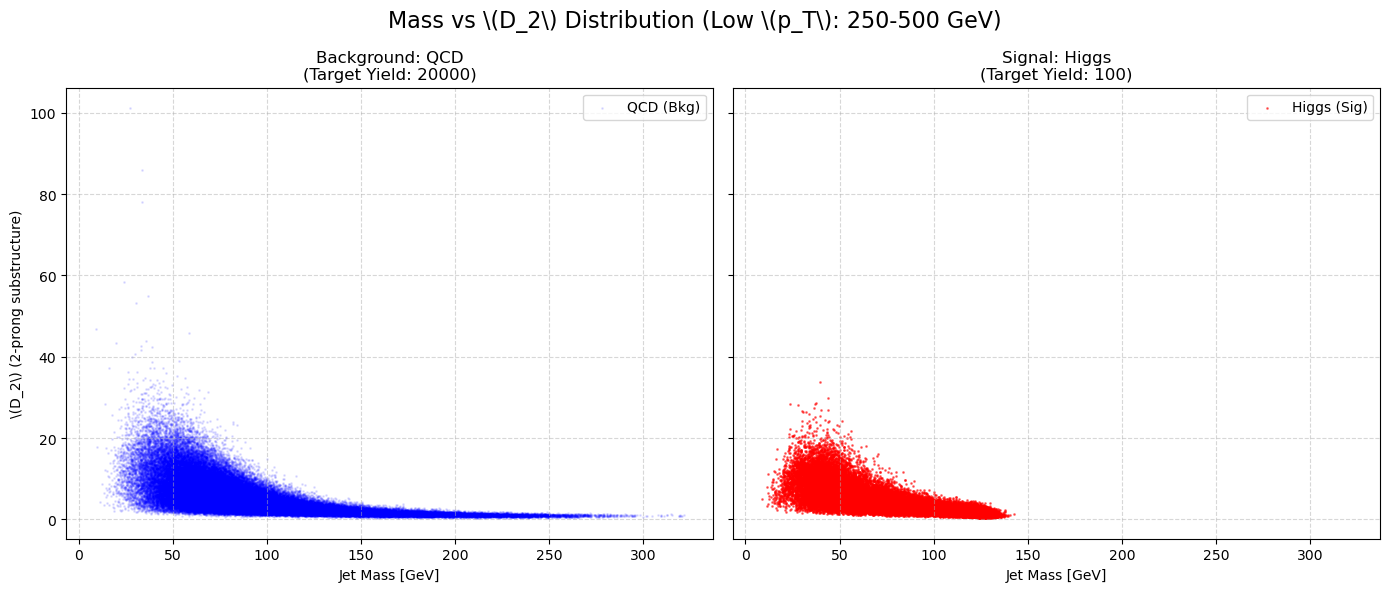

In [5]:

# 1. Define the paths
folder = "uwphys434/Sample_pt_250_500-20261104T215933Z-1-001/Sample_pt_250_500"
path_qcd = f"{folder}/qcd_100000_pt_250_500.h5"
path_higgs = f"{folder}/higgs_100000_pt_250_500.h5"

# 2. Load the data
with h5py.File(path_qcd, 'r') as f:
    qcd_array = f['qcd_100000_pt_250_500'][:] 
with h5py.File(path_higgs, 'r') as f:
    higgs_array = f['higgs_100000_pt_250_500'][:] 

# --- looking at the first row to find mass and d2 ---
# printing the mean of each column to help figure out which is which
print("Mean value of each of the 14 columns:")
print(f"QCD:   {np.mean(qcd_array, axis=0).round(2)}")
print(f"Higgs: {np.mean(higgs_array, axis=0).round(2)}")



mass_idx = 3  
d2_idx = 6  

df_qcd = pd.DataFrame({'mass': qcd_array[:, mass_idx], 'd2': qcd_array[:, d2_idx]})
df_higgs = pd.DataFrame({'mass': higgs_array[:, mass_idx], 'd2': higgs_array[:, d2_idx]})

# 3. Apply weights
target_yield_sig = 100
target_yield_bkg = 20000
weight_sig = target_yield_sig / len(df_higgs)
weight_bkg = target_yield_bkg / len(df_qcd)

# 4. Make the scatter plot
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6), sharex=True, sharey=True)

# Plot Background (QCD)
ax1.scatter(df_qcd['mass'], df_qcd['d2'], s=1, alpha=0.1, color='blue', label='QCD (Bkg)')
ax1.set_title(f'Background: QCD\n(Target Yield: {target_yield_bkg})')
ax1.set_xlabel('Jet Mass [GeV]')
ax1.set_ylabel(r'\(D_2\) (2-prong substructure)')
ax1.legend()
ax1.grid(True, linestyle='--', alpha=0.5)

# Plot Signal (Higgs)
ax2.scatter(df_higgs['mass'], df_higgs['d2'], s=1, alpha=0.5, color='red', label='Higgs (Sig)')
ax2.set_title(f'Signal: Higgs\n(Target Yield: {target_yield_sig})')
ax2.set_xlabel('Jet Mass [GeV]')
ax2.legend()
ax2.grid(True, linestyle='--', alpha=0.5)

plt.suptitle(r'Mass vs \(D_2\) Distribution (Low \(p_T\): 250-500 GeV)', fontsize=16)
plt.tight_layout()
plt.show()

# Lab 5 - Final Project Proposal - LHC Data
For my final project, I will analyze the sample LHC data provided in lab to investigate the detection of the Higgs boson against the QCD background. The data is divided into two folders based on transverse momentum ranges: pt_250_500 and pt_1000_1200. I plan to first explore the data for patterns and differences between the Higgs signal and QCD background, including how these change between the two transverse momentum ranges. From there, I will use statistical methods to investigate how well the Higgs signal can be distinguished from the background and calculate its statistical significance.

In [6]:



# Paths to the pickle files
higgs_path = Path(
    "uwphys434/Sample_pt_250_500-20261104T215933Z-1-001/"
    "Sample_pt_250_500/higgs_100000_pt_250_500.pkl"
)

qcd_path = Path(
    "uwphys434/Sample_pt_250_500-20261104T215933Z-1-001/"
    "Sample_pt_250_500/qcd_100000_pt_250_500.pkl"
)

# Load the pickle files
def load_pickle(path):
    if not path.exists():
        raise FileNotFoundError(
            f"Could not find {path}\n"
            f"Current working directory: {Path.cwd()}"
        )

    with open(path, "rb") as file:
        return pickle.load(file)

higgs_data = load_pickle(higgs_path)
qcd_data = load_pickle(qcd_path)


# inspect the contents of each file
def inspect_data(data, name, indent=0):
    spacing = " " * indent

    print(f"\n{spacing}{name}")
    print(f"{spacing}{'-' * len(name)}")
    print(f"{spacing}Object type: {type(data)}")

    # If the data is a pandas DataFrame
    if isinstance(data, pd.DataFrame):
        print(f"{spacing}Shape: {data.shape}")
        print(f"{spacing}Column names:")
        print(data.columns.tolist())
        display(data.head())

        print("\nSummary statistics:")
        display(data.describe())

    # If the data is a dictionary
    elif isinstance(data, dict):
        print(f"{spacing}Dictionary keys: {list(data.keys())}")

        for key, value in data.items():
            inspect_data(value, f"Key: {key}", indent + 4)

    # If the data is a NumPy array
    elif isinstance(data, np.ndarray):
        print(f"{spacing}Shape: {data.shape}")
        print(f"{spacing}Data type: {data.dtype}")

        if data.ndim == 2:
            print(f"{spacing}First five rows:")
            print(data[:5])

            print(f"\n{spacing}Column statistics:")
            stats = pd.DataFrame({
                "Column": np.arange(data.shape[1]),
                "Mean": np.mean(data, axis=0),
                "Std": np.std(data, axis=0),
                "Min": np.min(data, axis=0),
                "Max": np.max(data, axis=0),
                "Zero (%)": np.mean(data == 0, axis=0) * 100
            })
            display(stats)

    # If the data is a list or tuple
    elif isinstance(data, (list, tuple)):
        print(f"{spacing}Number of elements: {len(data)}")

        for i, value in enumerate(data):
            inspect_data(value, f"Element {i}", indent + 4)

    else:
        print(f"{spacing}Contents: {repr(data)[:1000]}")


# Inspect both datasets
inspect_data(higgs_data, "HIGGS DATA")
inspect_data(qcd_data, "QCD DATA")


HIGGS DATA
----------
Object type: <class 'pandas.core.frame.DataFrame'>
Shape: (100000, 14)
Column names:
['pt', 'eta', 'phi', 'mass', 'ee2', 'ee3', 'd2', 'angularity', 't1', 't2', 't3', 't21', 't32', 'KtDeltaR']


,pt,eta,phi,mass,ee2,ee3,d2,angularity,t1,t2,t3,t21,t32,KtDeltaR
0,472.074292,0.137052,-2.535145,125.150365,0.126581,0.002633,1.298020,0.008218,0.739787,0.283689,0.174944,0.383474,0.616674,0.557407
1,470.405678,-0.039157,0.069669,130.552672,0.118071,0.002379,1.445626,0.013822,0.747927,0.234281,0.193354,0.313240,0.825308,0.704650
2,438.008357,-0.181139,-3.031083,125.703063,0.167344,0.004623,0.986597,0.004545,1.001379,0.440523,0.218649,0.439917,0.496338,0.487496
3,484.860421,0.251986,2.855706,126.215853,0.119238,0.002066,1.218467,0.006740,0.761892,0.228160,0.193810,0.299465,0.849449,0.594872
4,486.141137,-1.917812,-2.221953,132.182504,0.103632,0.001438,1.291784,0.000398,0.722656,0.166851,0.148080,0.230886,0.887497,0.678118



Summary statistics:


,pt,eta,phi,mass,ee2,ee3,d2,angularity,t1,t2,t3,t21,t32,KtDeltaR
count,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000
mean,447.386623,-0.000899,0.002112,114.892387,0.125630,0.002704,1.966660,0.004289,0.901415,0.309755,0.225898,0.348189,0.755682,0.526579
std,44.771106,0.899305,1.813868,25.351070,0.043319,0.001993,2.500585,0.004289,0.217625,0.192411,0.142562,0.199348,0.128628,0.206267
min,250.076799,-3.202213,-3.141587,8.971221,0.006938,0.000002,0.275143,0.000002,0.491827,0.051114,0.038887,0.034160,0.090195,0.011027
25%,430.570091,-0.644074,-1.562480,122.351865,0.109582,0.001568,0.781870,0.001296,0.756085,0.162126,0.130284,0.191479,0.687105,0.474505
50%,464.956021,0.000693,0.005000,125.289912,0.136062,0.002311,1.125611,0.002951,0.857385,0.244256,0.177881,0.293399,0.785419,0.539176
75%,479.833881,0.646856,1.577208,126.329140,0.149558,0.003464,1.820329,0.005684,0.985300,0.408165,0.265786,0.464920,0.850923,0.640279
max,494.205477,3.264195,3.141444,142.439607,0.318725,0.030043,33.722824,0.060482,4.204353,2.446424,1.024776,0.983046,0.981718,1.078074



QCD DATA
--------
Object type: <class 'pandas.core.frame.DataFrame'>
Shape: (100000, 14)
Column names:
['pt', 'eta', 'phi', 'mass', 'ee2', 'ee3', 'd2', 'angularity', 't1', 't2', 't3', 't21', 't32', 'KtDeltaR']


,pt,eta,phi,mass,ee2,ee3,d2,angularity,t1,t2,t3,t21,t32,KtDeltaR
0,489.631389,1.955969,1.803007,125.298720,0.099409,0.003247,3.304886,0.000528,0.846096,0.586658,0.439468,0.693370,0.749105,0.333731
1,401.041884,-1.170413,0.188817,88.047054,0.101181,0.002527,2.439089,0.001561,0.852379,0.517657,0.336052,0.607308,0.649178,0.477481
2,447.487556,1.861736,-2.326646,85.794174,0.069372,0.001375,4.118371,0.000197,0.979133,0.815123,0.700152,0.832495,0.858953,0.117091
3,402.652836,1.276421,-1.124176,42.947328,0.032095,0.000266,8.038338,0.001144,1.020193,0.664347,0.617499,0.651197,0.929482,0.054606
4,484.257672,-1.272225,1.966794,59.542227,0.038348,0.000358,6.353842,0.001619,0.875408,0.436270,0.376816,0.498362,0.863723,0.095201



Summary statistics:


,pt,eta,phi,mass,ee2,ee3,d2,angularity,t1,t2,t3,t21,t32,KtDeltaR
count,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,1.000000e+05,100000.000000,1.000000e+05,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000
mean,445.708383,-0.002447,-0.002548,97.738041,0.089894,3.524497e-03,5.209383,4.941442e-03,0.913344,0.590302,0.476382,0.649212,0.805052,0.320726
std,34.824328,1.223938,1.813190,43.492923,0.065269,6.034649e-03,4.285187,5.576030e-03,0.155764,0.192134,0.171263,0.194495,0.104633,0.264540
min,250.125101,-3.240244,-3.141537,9.292817,0.002392,6.406594e-07,0.281344,5.803207e-07,0.392616,0.044932,0.026275,0.035544,0.077015,0.004970
25%,425.580984,-0.943242,-1.577321,67.195971,0.042505,5.076771e-04,2.175551,6.780458e-04,0.820499,0.453505,0.344726,0.519197,0.753088,0.094502
50%,448.447635,-0.006611,0.008342,88.126862,0.070525,1.366397e-03,3.851124,2.884777e-03,0.902288,0.608477,0.484189,0.680241,0.824019,0.244613
75%,471.773128,0.940265,1.567191,118.543683,0.118559,3.796792e-03,6.873730,7.505375e-03,0.977596,0.744121,0.611007,0.803194,0.880149,0.495818
max,499.999840,3.192603,3.141572,321.397993,0.495944,1.162739e-01,101.156561,5.360182e-02,3.941721,1.780207,1.111759,0.991104,0.988284,1.270750


Shown above is an overview of the data and all of the column names with the means, standard deviation, min, and different quartiles for the higgs and qcd in the sample_pt_250_500 folder.

As shown above the higgs data has an average mass of 114.89 and a median of 125.29 which makes sense since the mass of a higgs boson is ~125 GeV/c^2. for the QCD background the mean for mass is ~97.74 and the median is ~88.13.

for d_2: the mean for higgs data is ~1.966 and mean for QCD is ~5.209

In order to find out how well the higgs signal can be distinguished from the background signal, I'll start with a histogram of the higgs over the background and scan to see how much of the background I can reject.

The following section will focus on d_2 cuts to increase significance.

Total Higgs yield: 100.0
Total QCD   yield: 20000.0


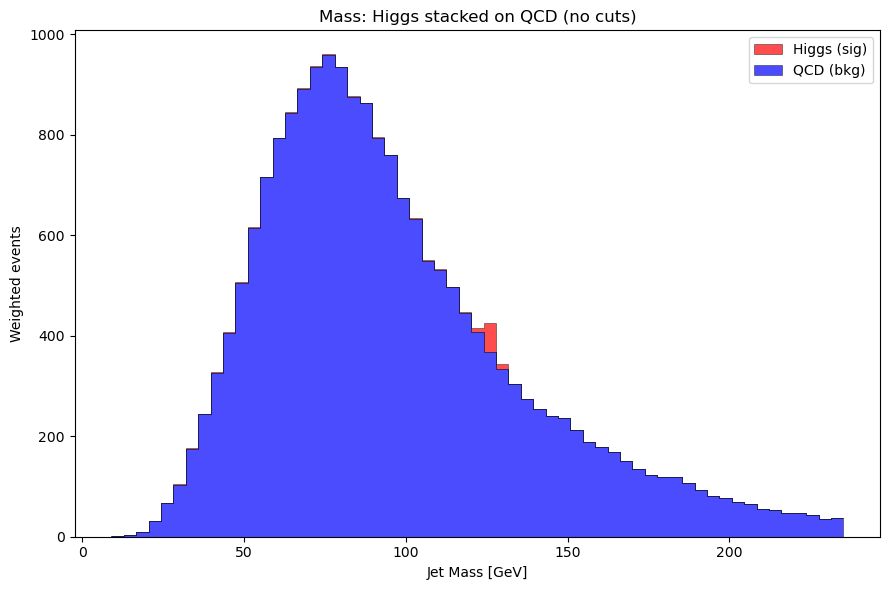

In [7]:
# Per-event weights (arrays, same length as dataframes)
w_sig_arr = np.full(len(df_higgs), weight_sig)
w_bkg_arr = np.full(len(df_qcd),  weight_bkg)

print(f"Total Higgs yield: {w_sig_arr.sum():.1f}")
print(f"Total QCD   yield: {w_bkg_arr.sum():.1f}")

# Stacked histogram: QCD on bottom, Higgs on top (both weighted)
fig, ax = plt.subplots(figsize=(9, 6))
bins_m = np.linspace(min(df_qcd['mass'].min(), df_higgs['mass'].min()),
                     max(np.percentile(df_qcd['mass'], 99),
                         np.percentile(df_higgs['mass'], 99)), 60)

ax.hist([df_qcd['mass'], df_higgs['mass']],
        bins=bins_m,
        weights=[w_bkg_arr, w_sig_arr],
        stacked=True,
        histtype='stepfilled',
        alpha=0.7,
        color=['blue', 'red'],
        label=['QCD (bkg)', 'Higgs (sig)'],
        edgecolor='black', linewidth=0.4)
ax.set_xlabel('Jet Mass [GeV]')
ax.set_ylabel('Weighted events')
ax.set_title('Mass: Higgs stacked on QCD (no cuts)')
ax.legend()
plt.tight_layout()
plt.show()

In [8]:
def significance(S, B):
    return S / np.sqrt(B) if B > 0 else 0.0

d2_s = df_higgs['d2'].values
d2_b = df_qcd['d2'].values
d2_all = np.concatenate([d2_s, d2_b])

# Scan grid: 1st to 99th percentile of the combined d2
grid = np.linspace(np.percentile(d2_all, 1), np.percentile(d2_all, 99), 300)

def scan_d2_cut(d2_s, d2_b, direction='high', min_bkg=5.0):
    best = None
    for cut in grid:
        if direction == 'high':
            ms = d2_s > cut
            mb = d2_b > cut
        else:
            ms = d2_s < cut
            mb = d2_b < cut
        S = w_sig_arr[ms].sum()
        B = w_bkg_arr[mb].sum()
        if B < min_bkg:            # skip empty tails that fake high S/sqrt(B)
            continue
        sig = significance(S, B)
        if best is None or sig > best['sig']:
            best = dict(cut=cut, sig=sig, S=S, B=B, direction=direction)
    return best

best_high = scan_d2_cut(d2_s, d2_b, 'high')
best_low  = scan_d2_cut(d2_s, d2_b, 'low')

print("Best HIGH-d2 cut:", best_high)
print("Best LOW-d2  cut:", best_low)

best = best_high if best_high['sig'] > best_low['sig'] else best_low
print("\nCHOSEN best d2 cut:", best)

Best HIGH-d2 cut: {'cut': np.float64(0.47289040192761594), 'sig': np.float64(0.6937235478919885), 'S': np.float64(98.07200000000003), 'B': np.float64(19985.6), 'direction': 'high'}
Best LOW-d2  cut: {'cut': np.float64(0.8203062293754163), 'sig': np.float64(1.7609380008079796), 'S': np.float64(28.16400000000001), 'B': np.float64(255.79999999999995), 'direction': 'low'}

CHOSEN best d2 cut: {'cut': np.float64(0.8203062293754163), 'sig': np.float64(1.7609380008079796), 'S': np.float64(28.16400000000001), 'B': np.float64(255.79999999999995), 'direction': 'low'}


In [9]:
# Baseline: no d2 cut
S0 = w_sig_arr.sum()
B0 = w_bkg_arr.sum()
print(f"No d2 cut:              S/√B = {significance(S0,B0):6.3f}   (S={S0:.1f}, B={B0:.1f})")

# Very large d2 cut (keep only top 5% of d2)
very_high = np.percentile(d2_all, 95)
S_hi = w_sig_arr[d2_s > very_high].sum()
B_hi = w_bkg_arr[d2_b > very_high].sum()
print(f"Very large d2 cut (>{very_high:.3g}): S/√B = {significance(S_hi,B_hi):6.3f}   (S={S_hi:.1f}, B={B_hi:.1f})")

# Best cut from scan
print(f"Best scan cut ({best['direction']} {best['cut']:.3g}):    S/√B = {best['sig']:6.3f}   (S={best['S']:.1f}, B={best['B']:.1f})")

No d2 cut:              S/√B =  0.707   (S=100.0, B=20000.0)
Very large d2 cut (>11.8): S/√B =  0.040   (S=1.6, B=1673.0)
Best scan cut (low 0.82):    S/√B =  1.761   (S=28.2, B=255.8)


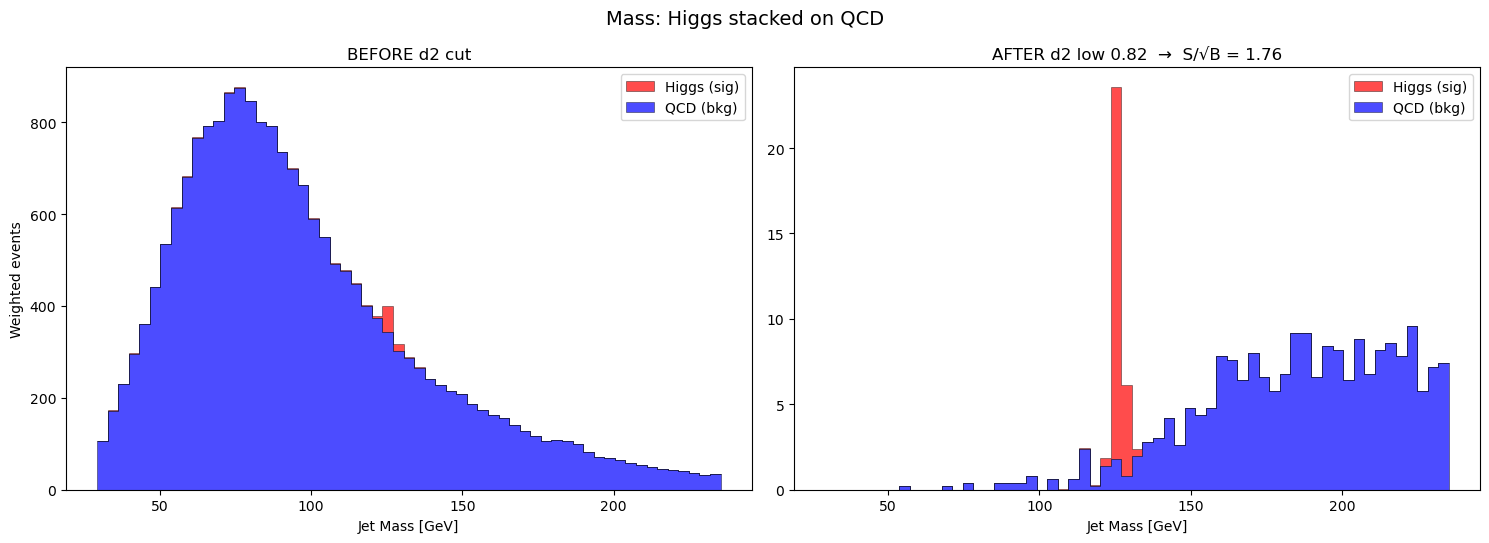

In [10]:
# Apply the best cut
if best['direction'] == 'high':
    mask_s = d2_s > best['cut']
    mask_b = d2_b > best['cut']
else:
    mask_s = d2_s < best['cut']
    mask_b = d2_b < best['cut']

mass_s_cut = df_higgs['mass'].values[mask_s]
mass_b_cut = df_qcd['mass'].values[mask_b]
w_s_cut = w_sig_arr[mask_s]
w_b_cut = w_bkg_arr[mask_b]

# Shared mass binning
bins_m = np.linspace(
    min(np.percentile(df_qcd['mass'], 1),  np.percentile(df_higgs['mass'], 1)),
    max(np.percentile(df_qcd['mass'], 99), np.percentile(df_higgs['mass'], 99)),
    60)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# Left: stacked, BEFORE cut
axes[0].hist([df_qcd['mass'], df_higgs['mass']],
             bins=bins_m, weights=[w_bkg_arr, w_sig_arr],
             stacked=True, histtype='stepfilled', alpha=0.7,
             color=['blue', 'red'], label=['QCD (bkg)', 'Higgs (sig)'],
             edgecolor='black', linewidth=0.4)
axes[0].set_title('BEFORE d2 cut')
axes[0].set_xlabel('Jet Mass [GeV]'); axes[0].set_ylabel('Weighted events')
axes[0].legend()

# Right: stacked, AFTER cut
axes[1].hist([mass_b_cut, mass_s_cut],
             bins=bins_m, weights=[w_b_cut, w_s_cut],
             stacked=True, histtype='stepfilled', alpha=0.7,
             color=['blue', 'red'], label=['QCD (bkg)', 'Higgs (sig)'],
             edgecolor='black', linewidth=0.4)
axes[1].set_title(f'AFTER d2 {best["direction"]} {best["cut"]:.3g}  →  S/√B = {best["sig"]:.2f}')
axes[1].set_xlabel('Jet Mass [GeV]')
axes[1].legend()

plt.suptitle('Mass: Higgs stacked on QCD', fontsize=14)
plt.tight_layout()
plt.show()